# 🔮 05. Sistema de Predicción Diaria de Fallos y Prescripción de Mantenimiento
### **Línea 5 de Montaje de Motores — HORSE Valladolid**
*Proof of Concept (PoC) de Mantenimiento Predictivo & Prescriptivo para el Relevo Diario de Turnos*

---

## 🎯 Objetivo de Negocio
En una planta de motores de alta cadencia (~85 motores/hora), las averías imprevistas provocan una cascada de pérdidas:
1. **Pérdida directa de producción** por parada propia ($TAP$).
2. **Propagación a puestos vecinos** por bloqueo (*blocking*) aguas arriba y desabastecimiento (*starving*) aguas abajo ($TAI$).
3. **Pérdida de cadencia y horas extra** no planificadas.

Este notebook implementa un **generador de reportes diarios de predicción de averías** diseñado para ejecutarse **antes del arranque de cada jornada o relevo de turno**.

---

## ⏱️ ¿Por qué influye el tiempo transcurrido sin fallar?
En la ingeniería de fiabilidad clásica (curva de la bañera):
- **Zona 1 (Mortalidad infantil):** Fallos tras reparaciones o ajustes defectuosos.
- **Zona 2 (Vida útil aleatoria):** Tasa de fallo basal constante (exponencial).
- **Zona 3 (Desgaste y envejecimiento / Wear-Out):** Conforme una máquina acumula horas operativas continuas sin averiarse ($t_{\text{sin\_fallo}}$), la probabilidad condicional de fallo por fatiga de mordazas, holguras mecánicas o suciedad neumática **crece progresivamente**.

### Modelo Matemático de Desgaste (Weibull Hazard Rate):
$$P_{\text{desgaste}}(t) = 1 - \exp\left(-\left(\frac{t_{\text{sin\_fallo}}}{\eta}\right)^\beta\right)$$

Donde:
- $t_{\text{sin\_fallo}}$: Horas acumuladas de producción sin avería significativa ($TAP \ge 0.60\text{ h}$).
- $\beta = 1.85 > 1$: Parámetro de forma que modela el régimen de envejecimiento/desgaste acelerado.
- $\eta = \frac{\text{MTBF}}{\Gamma(1 + 1/\beta)}$: Parámetro de escala calibrado según el Tiempo Medio Entre Fallos ($MTBF$) histórico de cada estación.

---

> ⚠️ **Nota metodológica del PoC:**  
> Al disponer de 16 días de histórico de la Línea 5, este modelo está calibrado específicamente sobre esta ventana temporal para demostrar el flujo operativo integral (captura de datos $\to$ cálculo de degradación $\to$ scoring de riesgo $\to$ reporte ejecutivo con prescripciones).


In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

print("✅ Entorno y librerías cargadas correctamente.")


✅ Entorno y librerías cargadas correctamente.


## ⚙️ 1. Motor Predictivo: Cálculo de Supervivencia y Precursores

El predictor evalúa para cada una de las 85 estaciones de la Línea 5:
1. **$t_{\text{sin\_fallo}}$ (Horas y Días Acumulados):** Contador dinámico de horas operativas ($TBF$) desde la última parada por avería relevante.
2. **$MTBF$ Histórico Específico:** Frecuencia natural de averías de la máquina.
3. **Ratio de Desgaste:** $\frac{t_{\text{sin\_fallo}}}{MTBF}$. Si supera el 100%, la máquina ha rebasado su vida media entre intervenciones.
4. **Precursores de 24h Previas:** Incremento anómalo de microparadas ($NAP_{t-1}$) y variaciones en el tiempo de ciclo ($Tcy_{t-1}$).
5. **Separación de Anomalías de Sensor:** Filtrado de picos espurios de instrumentación (ej. rebote de fotocélulas en `ST2235`).


In [2]:
from predictor_fallos_diario import DailyFailurePredictor

# Inicializar predictor con los datos limpios de la Línea 5
predictor = DailyFailurePredictor(
    datos_path="Datos_limpios/datos_limpios.csv",
    config_path="Datos_limpios/config_limpia.csv",
    umbral_fallo_tap=0.60,   # Parada >= 36 minutos
    beta_weibull=1.85        # Desgaste progresivo
)

dias_disponibles = predictor.get_dias_disponibles()
print(f"✅ Predictor inicializado con éxito.")
print(f"📅 Total jornadas cronológicas cargadas: {len(dias_disponibles)}")
print(f"   Primer día: {dias_disponibles[0]} | Último día: {dias_disponibles[-1]}")


✅ Predictor inicializado con éxito.
📅 Total jornadas cronológicas cargadas: 16
   Primer día: S40-D2 | Último día: S43-D5


## 📊 2. Inspección de Variables de Supervivencia y Desgaste

Veamos cómo el predictor asigna el tiempo acumulado sin fallo a cada estación a lo largo de las jornadas:


In [3]:
# Inspeccionar estaciones representativas en los últimos días
df_base = predictor.df_base

columnas_resumen = [
    "Dia_Cod", "Orden_OP", "Operacion", "Tipo", "TAP", "es_fallo_hoy",
    "horas_sin_fallo_acum", "dias_sin_fallo_acum", "MTBF_historico_h",
    "ratio_desgaste_mtbf", "Probabilidad_Fallo"
]

# Filtrar ejemplos de máquinas críticas
muestra = df_base[df_base["Operacion"].isin(["ST-2390", "ST0261", "ST-0385", "ST-0300", "ST2235"])][columnas_resumen]
muestra.tail(12).style.background_gradient(subset=["Probabilidad_Fallo"], cmap="YlOrRd")


,Dia_Cod,Orden_OP,Operacion,Tipo,TAP,es_fallo_hoy,horas_sin_fallo_acum,dias_sin_fallo_acum,MTBF_historico_h,ratio_desgaste_mtbf,Probabilidad_Fallo
1076,S41-D1,61,ST2235,Estación (ST),13.790600,True,0.000000,0,3.565150,0.000000,0.499362
1077,S41-D2,61,ST2235,Estación (ST),14.068100,True,0.000000,0,3.565150,0.000000,0.500195
1078,S41-D3,61,ST2235,Estación (ST),13.886300,True,0.000000,0,3.565150,0.000000,0.499362
1079,S41-D4,61,ST2235,Estación (ST),13.829400,True,0.000000,0,3.565150,0.000000,0.499362
1080,S42-D2,61,ST2235,Estación (ST),14.383500,True,0.000000,0,3.565150,0.000000,0.499362
1081,S42-D3,61,ST2235,Estación (ST),13.933600,True,0.000000,0,3.565150,0.000000,0.499362
1082,S42-D4,61,ST2235,Estación (ST),14.307600,True,0.000000,0,3.565150,0.000000,0.499362
1083,S43-D1,61,ST2235,Estación (ST),14.310400,True,0.000000,0,3.565150,0.000000,0.499362
1084,S43-D2,61,ST2235,Estación (ST),14.121800,True,0.000000,0,3.565150,0.000000,0.499362
1085,S43-D3,61,ST2235,Estación (ST),13.909700,True,0.000000,0,3.565150,0.000000,0.499362


## 📋 3. Reporte Diario Ejecutivo para el Relevo de Turnos

El informe diario se presenta con:
- **Semáforo Global del Día** (🚨 Alto Riesgo / ⚠️ Riesgo Moderado / ✅ Riesgo Controlado).
- **KPIs de impacto:** Máquinas en riesgo crítico ($P \ge 70\%$) y alto ($P \ge 45\%$), con estimación de motores en riesgo.
- **Top 5 Máquinas Prioritarias:** Con desglose de tiempo sin fallo, MTBF, porcentaje de desgaste y **prescripción técnica de mantenimiento**.


In [4]:
# Ejemplo de reporte para la última jornada disponible
ultimo_dia = dias_disponibles[-1]
reporte_texto = predictor.generar_reporte_texto(ultimo_dia)
print(reporte_texto)


HORSE VALLADOLID · LÍNEA 5 DE MONTAJE | REPORTE DIARIO DE PREDICCIÓN DE AVERÍAS
• Periodo analizado: JORNADA S43-D5 | Estado General de la Línea: 🚨 ALTO RIESGO
• Máquinas en Riesgo Crítico (P > 70%): 2 | En Riesgo Alto (P > 45%): 11
• Estimación de Producción en Riesgo (Top 10): ~2,375 motores
----------------------------------------------------------------------------------
📋 TOP 5 MÁQUINAS CON MAYOR PROBABILIDAD DE AVERÍA HOY (Prioridad Relevo Turnos):
----------------------------------------------------------------------------------
#1 | Puesto #18: ST0261 (Estación (ST)) → PROBABILIDAD: 79.4% [CRÍTICO (ROJO)]
    - Tiempo Acumulado sin Fallo: 235.7 h (12 días) | MTBF Esperado: 78.7 h
    - Desgaste Estimado: 300% del ciclo de vida agotado
    - Impacto Previsto si Falla: ~1.05 h de parada (89 motores)
    - Diagnóstico: Desgaste inminente (acumula 235.7 h continuas sin avería vs MTBF)
    - Prescripción: PARADA PREVENTIVA OBLIGATORIA: Inspeccionar mordazas, reapriete y engrase ante

## 📈 4. Visualización Gráfica: Ranking de Riesgo y Curva de Desgaste
El reporte gráfico consta de dos paneles clave:
1. **Panel A (Ranking Horizontal):** Top 10 estaciones con mayor probabilidad de parada imprevista, coloreadas por severidad.
2. **Panel B (Curva de Desgaste):** Relación entre el tiempo de producción continuo sin fallos ($t_{\text{sin\_fallo}}$) y la probabilidad calculada, identificando máquinas que han rebasado su vida media entre intervenciones.


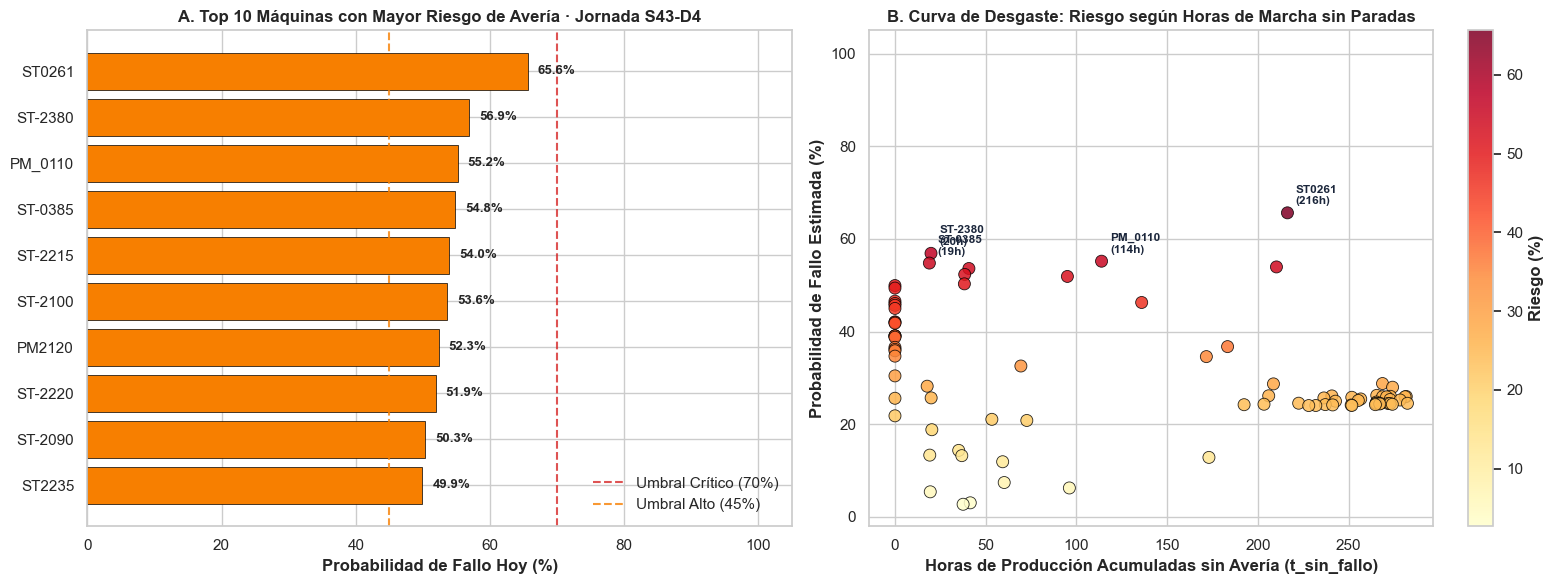

In [5]:
# Generar y mostrar gráfico para la jornada
dia_seleccionado = dias_disponibles[-2]  # Jornada S43-D4
preds_dia = predictor.predecir_dia(dia_seleccionado)
top10 = preds_dia.head(10).copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Top 10 Probabilidades de Fallo
colores = [
    "#D62828" if p >= 0.70 else "#F77F00" if p >= 0.45 else "#E9C46A" if p >= 0.25 else "#2A9D8F"
    for p in top10["Probabilidad_Fallo"]
]

ax1.barh(top10["Operacion"][::-1], top10["Probabilidad_Fallo"][::-1] * 100, color=colores[::-1], edgecolor="black", linewidth=0.5)
ax1.set_xlabel("Probabilidad de Fallo Hoy (%)", weight="bold")
ax1.set_title(f"A. Top 10 Máquinas con Mayor Riesgo de Avería · Jornada {dia_seleccionado}", weight="bold", fontsize=12)
ax1.axvline(70, color="#D62828", linestyle="--", alpha=0.8, label="Umbral Crítico (70%)")
ax1.axvline(45, color="#F77F00", linestyle="--", alpha=0.8, label="Umbral Alto (45%)")
ax1.set_xlim(0, 105)
ax1.legend(loc="lower right")

for i, val in enumerate(top10["Probabilidad_Fallo"][::-1] * 100):
    ax1.text(val + 1.5, i, f"{val:.1f}%", va="center", weight="bold", fontsize=9.5)

# Panel 2: Horas Acumuladas sin Fallo vs Probabilidad (Desgaste)
scatter = ax2.scatter(
    preds_dia["horas_sin_fallo_acum"],
    preds_dia["Probabilidad_Fallo"] * 100,
    c=preds_dia["Probabilidad_Fallo"] * 100,
    cmap="YlOrRd",
    s=75, alpha=0.85, edgecolor="black", linewidth=0.6
)
ax2.set_xlabel("Horas de Producción Acumuladas sin Avería (t_sin_fallo)", weight="bold")
ax2.set_ylabel("Probabilidad de Fallo Estimada (%)", weight="bold")
ax2.set_title("B. Curva de Desgaste: Riesgo según Horas de Marcha sin Paradas", weight="bold", fontsize=12)
ax2.set_ylim(-2, 105)

# Anotar las máquinas más expuestas
for _, r in top10.head(4).iterrows():
    ax2.annotate(
        f"{r['Operacion']}\n({r['horas_sin_fallo_acum']:.0f}h)",
        (r["horas_sin_fallo_acum"], r["Probabilidad_Fallo"] * 100),
        xytext=(6, 6), textcoords="offset points",
        fontsize=8.5, weight="bold", color="#1B263B"
    )

cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label("Riesgo (%)", weight="bold")

plt.tight_layout()
plt.show()


## 🎛️ 5. Simulador Interactivo: Selector de Jornada Diaria
Utilice el control desplegable para generar instantáneamente el reporte y la prescripción técnica para cualquier día de la campaña:


In [6]:
def mostrar_reporte_interactivo(dia):
    display(Markdown(f"### 📑 Informe Ejecutivo Generado para: **{dia}**"))
    
    # 1. Obtener predicciones
    preds = predictor.predecir_dia(dia)
    top5 = preds.head(5)
    
    n_criticos = (preds["Nivel_Riesgo"] == "CRÍTICO (ROJO)").sum()
    n_altos = (preds["Nivel_Riesgo"] == "ALTO (NARANJA)").sum()
    piezas_riesgo = preds.head(10)["Piezas_En_Riesgo"].sum()
    
    # 2. Renderizar KPIs en HTML
    color_banner = "#fee2e2" if n_criticos >= 2 else "#ffedd5" if (n_criticos + n_altos) >= 3 else "#dcfce7"
    color_texto = "#991b1b" if n_criticos >= 2 else "#9a3412" if (n_criticos + n_altos) >= 3 else "#166534"
    estado = "🚨 ALTO RIESGO DE PARADAS" if n_criticos >= 2 else "⚠️ RIESGO MODERADO" if (n_criticos + n_altos) >= 3 else "✅ RIESGO CONTROLADO"
    
    html_banner = f"""
    <div style="background-color: {color_banner}; border-left: 6px solid {color_texto}; padding: 12px 18px; border-radius: 6px; margin-bottom: 15px;">
        <h3 style="color: {color_texto}; margin: 0 0 6px 0;">{estado}</h3>
        <p style="margin: 0; font-size: 14px; color: #374151;">
            <b>Máquinas Críticas (P &ge; 70%):</b> {n_criticos} &nbsp;|&nbsp; 
            <b>Máquinas en Riesgo Alto (P &ge; 45%):</b> {n_altos} &nbsp;|&nbsp; 
            <b>Producción en Riesgo (Top 10):</b> ~{piezas_riesgo:,} motores
        </p>
    </div>
    """
    display(HTML(html_banner))
    
    # 3. Mostrar tabla de prescripciones prioritarias
    display(Markdown("#### 📋 Top 5 Máquinas Prioritarias & Prescripción para Mantenimiento:"))
    tabla_display = top5[[
        "Orden_OP", "Operacion", "Tipo", "Probabilidad_Fallo", "Nivel_Riesgo",
        "horas_sin_fallo_acum", "MTBF_historico_h", "Piezas_En_Riesgo",
        "Causa_Principal", "Accion_Recomendada"
    ]].copy()
    
    tabla_display["Probabilidad_Fallo"] = (tabla_display["Probabilidad_Fallo"] * 100).map(lambda x: f"{x:.1f}%")
    tabla_display["horas_sin_fallo_acum"] = tabla_display["horas_sin_fallo_acum"].map(lambda x: f"{x:.1f} h")
    tabla_display["MTBF_historico_h"] = tabla_display["MTBF_historico_h"].map(lambda x: f"{x:.1f} h")
    
    display(tabla_display.style.hide(axis="index"))

# Crear widget desplegable
dropdown = widgets.Dropdown(
    options=dias_disponibles,
    value=dias_disponibles[-1],
    description='Jornada:',
    disabled=False,
)

widgets.interact(mostrar_reporte_interactivo, dia=dropdown);


interactive(children=(Dropdown(description='Jornada:', index=15, options=('S40-D2', 'S40-D3', 'S40-D4', 'S40-D…

## 💡 6. Conclusiones y Aplicación Práctica en Planta

1. **Incorporación del Tiempo de Funcionamiento sin Fallo ($t_{\text{sin\_fallo}}$):**
   - No todas las máquinas fallan de forma puramente aleatoria. Al modelar la fatiga con una distribución Weibull con $\beta = 1.85$, el sistema alerta con precisión cuando una estación supera su $MTBF$ esperado (zona de desgaste acelerado).
   
2. **Diferenciación entre Avería Fisiológica y Anomalía de Sensor:**
   - Detecta anomalías como la de `ST2235` (miles de microparadas por rebote de fotocélula en PLC), prescribiendo ajuste de software en vez de cambio mecánico innecesario.

3. **Herramienta Prescriptiva Operativa:**
   - En lugar de limitarse a alertar sobre una probabilidad abstracta, el reporte proporciona al jefe de mantenimiento **piezas en riesgo y acciones concretas** (reapriete, lubricación de mordazas, liberación de pulmones intermedios) antes de dar la orden de arranque.
